# Week 1: Exploration & Baseline

## 1. Environment Setup and Data Loading

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import vendor_api

# Import additional analysis tools
from sklearn import metrics
from lime.lime_tabular import LimeTabularExplainer
import shap

# Configure display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load the audit dataset
df_audit = pd.read_parquet("data/audit_sample.parquet")

# Initialize the vendor model and generate predictions
probs = vendor_api.predict_proba(df_audit)

# Verify successful setup
print("Dataset successfully loaded.")
print("Dataset shape:", df_audit.shape)
print("Vendor API successfully initialized.")
print("Prediction shape:", probs.shape)

Dataset successfully loaded.
Dataset shape: (10000, 20)
Vendor API successfully initialized.
Prediction shape: (10000, 2)


## 2. Exploratory Data Analysis

In [2]:
# Display the first five records
display(df_audit.head())

# Display dataset dimensions
print("Number of records:", df_audit.shape[0])
print("Number of columns:", df_audit.shape[1])

# Inspect column names and data types
df_audit.info()

,AGEP,SCHL,MAR,SEX,DIS,ESP,CIT,MIG,MIL,ANC,NATIVITY,DEAR,DEYE,DREM,PINCP,ESR,ST,FER,PUBCOV,STATE
0,86,18,2,2,2,1,2,3,3,4,1,1,2,2,11610.065047,1,42,1,1,NY
1,82,2,1,1,1,1,3,3,2,4,1,1,1,2,5047.650988,6,36,0,0,NY
2,67,19,3,1,2,0,3,1,1,2,2,2,2,2,45363.553969,5,36,0,1,NY
3,39,5,4,2,2,2,5,3,1,1,2,2,2,2,51892.354192,6,42,2,0,NY
4,76,23,1,2,1,1,5,1,1,2,1,2,1,1,20728.423711,4,42,1,1,NY


Number of records: 10000
Number of columns: 20
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   AGEP      10000 non-null  int64  
 1   SCHL      10000 non-null  int64  
 2   MAR       10000 non-null  int64  
 3   SEX       10000 non-null  int64  
 4   DIS       10000 non-null  int64  
 5   ESP       10000 non-null  int64  
 6   CIT       10000 non-null  int64  
 7   MIG       10000 non-null  int64  
 8   MIL       10000 non-null  int64  
 9   ANC       10000 non-null  int64  
 10  NATIVITY  10000 non-null  int64  
 11  DEAR      10000 non-null  int64  
 12  DEYE      10000 non-null  int64  
 13  DREM      10000 non-null  int64  
 14  PINCP     10000 non-null  float64
 15  ESR       10000 non-null  int64  
 16  ST        10000 non-null  int64  
 17  FER       10000 non-null  int64  
 18  PUBCOV    10000 non-null  int64  
 19  STATE     10000 non-null  str   

In [3]:
# Check missing values
print("Missing values per column:")
display(df_audit.isnull().sum())

# Check duplicate records
print("Duplicate records:", df_audit.duplicated().sum())

Missing values per column:


AGEP        0
SCHL        0
MAR         0
SEX         0
DIS         0
ESP         0
CIT         0
MIG         0
MIL         0
ANC         0
NATIVITY    0
DEAR        0
DEYE        0
DREM        0
PINCP       0
ESR         0
ST          0
FER         0
PUBCOV      0
STATE       0
dtype: int64

Duplicate records: 0


In [4]:
# Check missing values
print("Missing values per column:")
display(df_audit.isnull().sum())

# Check duplicate records
print("Duplicate records:", df_audit.duplicated().sum())

Missing values per column:


AGEP        0
SCHL        0
MAR         0
SEX         0
DIS         0
ESP         0
CIT         0
MIG         0
MIL         0
ANC         0
NATIVITY    0
DEAR        0
DEYE        0
DREM        0
PINCP       0
ESR         0
ST          0
FER         0
PUBCOV      0
STATE       0
dtype: int64

Duplicate records: 0


## 3. Feature Distributions

In [5]:
# Summary statistics for numerical features
display(df_audit[["AGEP", "PINCP"]].describe())

,AGEP,PINCP
count,10000.000000,10000.000000
mean,53.279300,37138.111643
std,20.730018,34191.261922
min,18.000000,1093.204033
25%,36.000000,15694.577460
50%,53.000000,27091.316811
75%,71.000000,46381.593404
max,89.000000,300000.000000


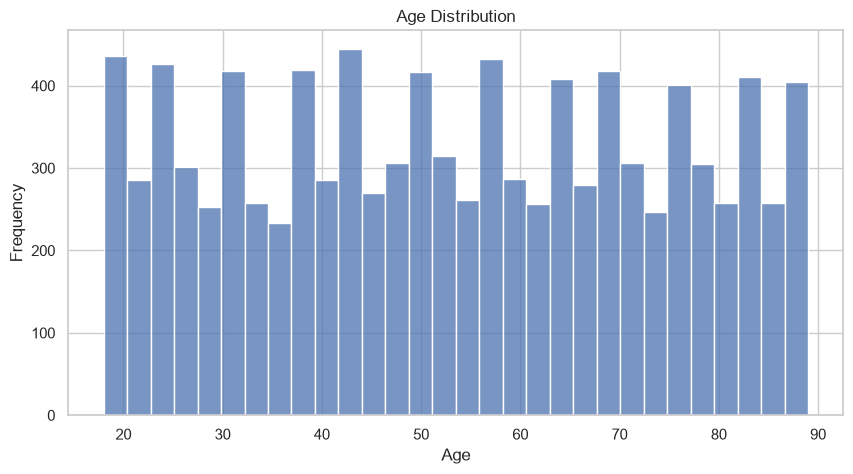

In [6]:
# Age distribution
plt.figure(figsize=(10, 5))

sns.histplot(data=df_audit, x="AGEP", bins=30)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

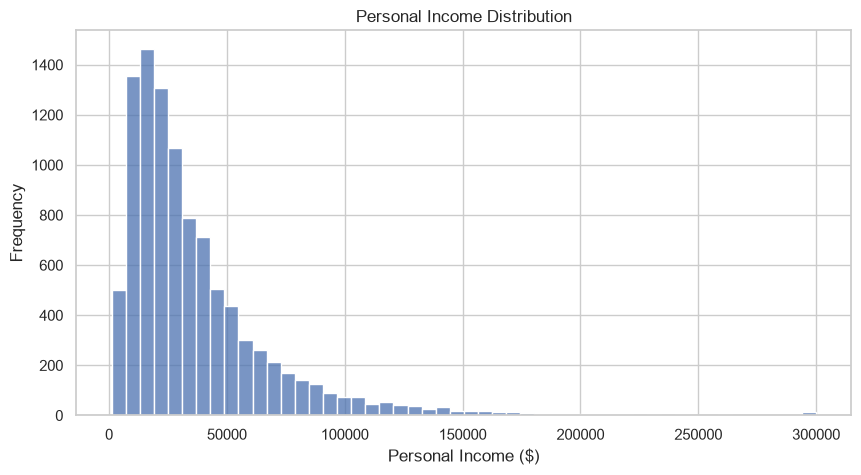

In [7]:
# Personal income distribution
plt.figure(figsize=(10, 5))

sns.histplot(data=df_audit, x="PINCP", bins=50)

plt.title("Personal Income Distribution")
plt.xlabel("Personal Income ($)")
plt.ylabel("Frequency")

plt.show()

In [8]:
# List of categorical features
categorical_features = [
    "SCHL", "MAR", "SEX", "DIS",
    "ESP", "CIT", "MIG", "MIL",
    "ANC", "NATIVITY", "DEAR", "DEYE",
    "DREM", "ESR", "ST", "FER"
]

# Display frequency and percentage for each feature
for feature in categorical_features:
    print(f"\nDistribution of {feature}:")

    distribution = pd.DataFrame({
        "Count": df_audit[feature].value_counts(dropna=False),
        "Percentage": df_audit[feature].value_counts(
            normalize=True, dropna=False
        ) * 100
    })

    display(distribution.round(2))


Distribution of SCHL:


,Count,Percentage
SCHL,,
7,450,4.50
20,444,4.44
4,443,4.43
2,437,4.37
21,437,4.37
19,435,4.35
12,428,4.28
10,425,4.25
13,424,4.24



Distribution of MAR:


,Count,Percentage
MAR,,
5,2050,20.50
3,2008,20.08
2,1992,19.92
4,1977,19.77
1,1973,19.73



Distribution of SEX:


,Count,Percentage
SEX,,
1,5031,50.31
2,4969,49.69


... (22 outputs left out)


Distribution of ST:


,Count,Percentage
ST,,
36,5022,50.22
42,4978,49.78



Distribution of FER:


,Count,Percentage
FER,,
1,3383,33.83
2,3355,33.55
0,3262,32.62


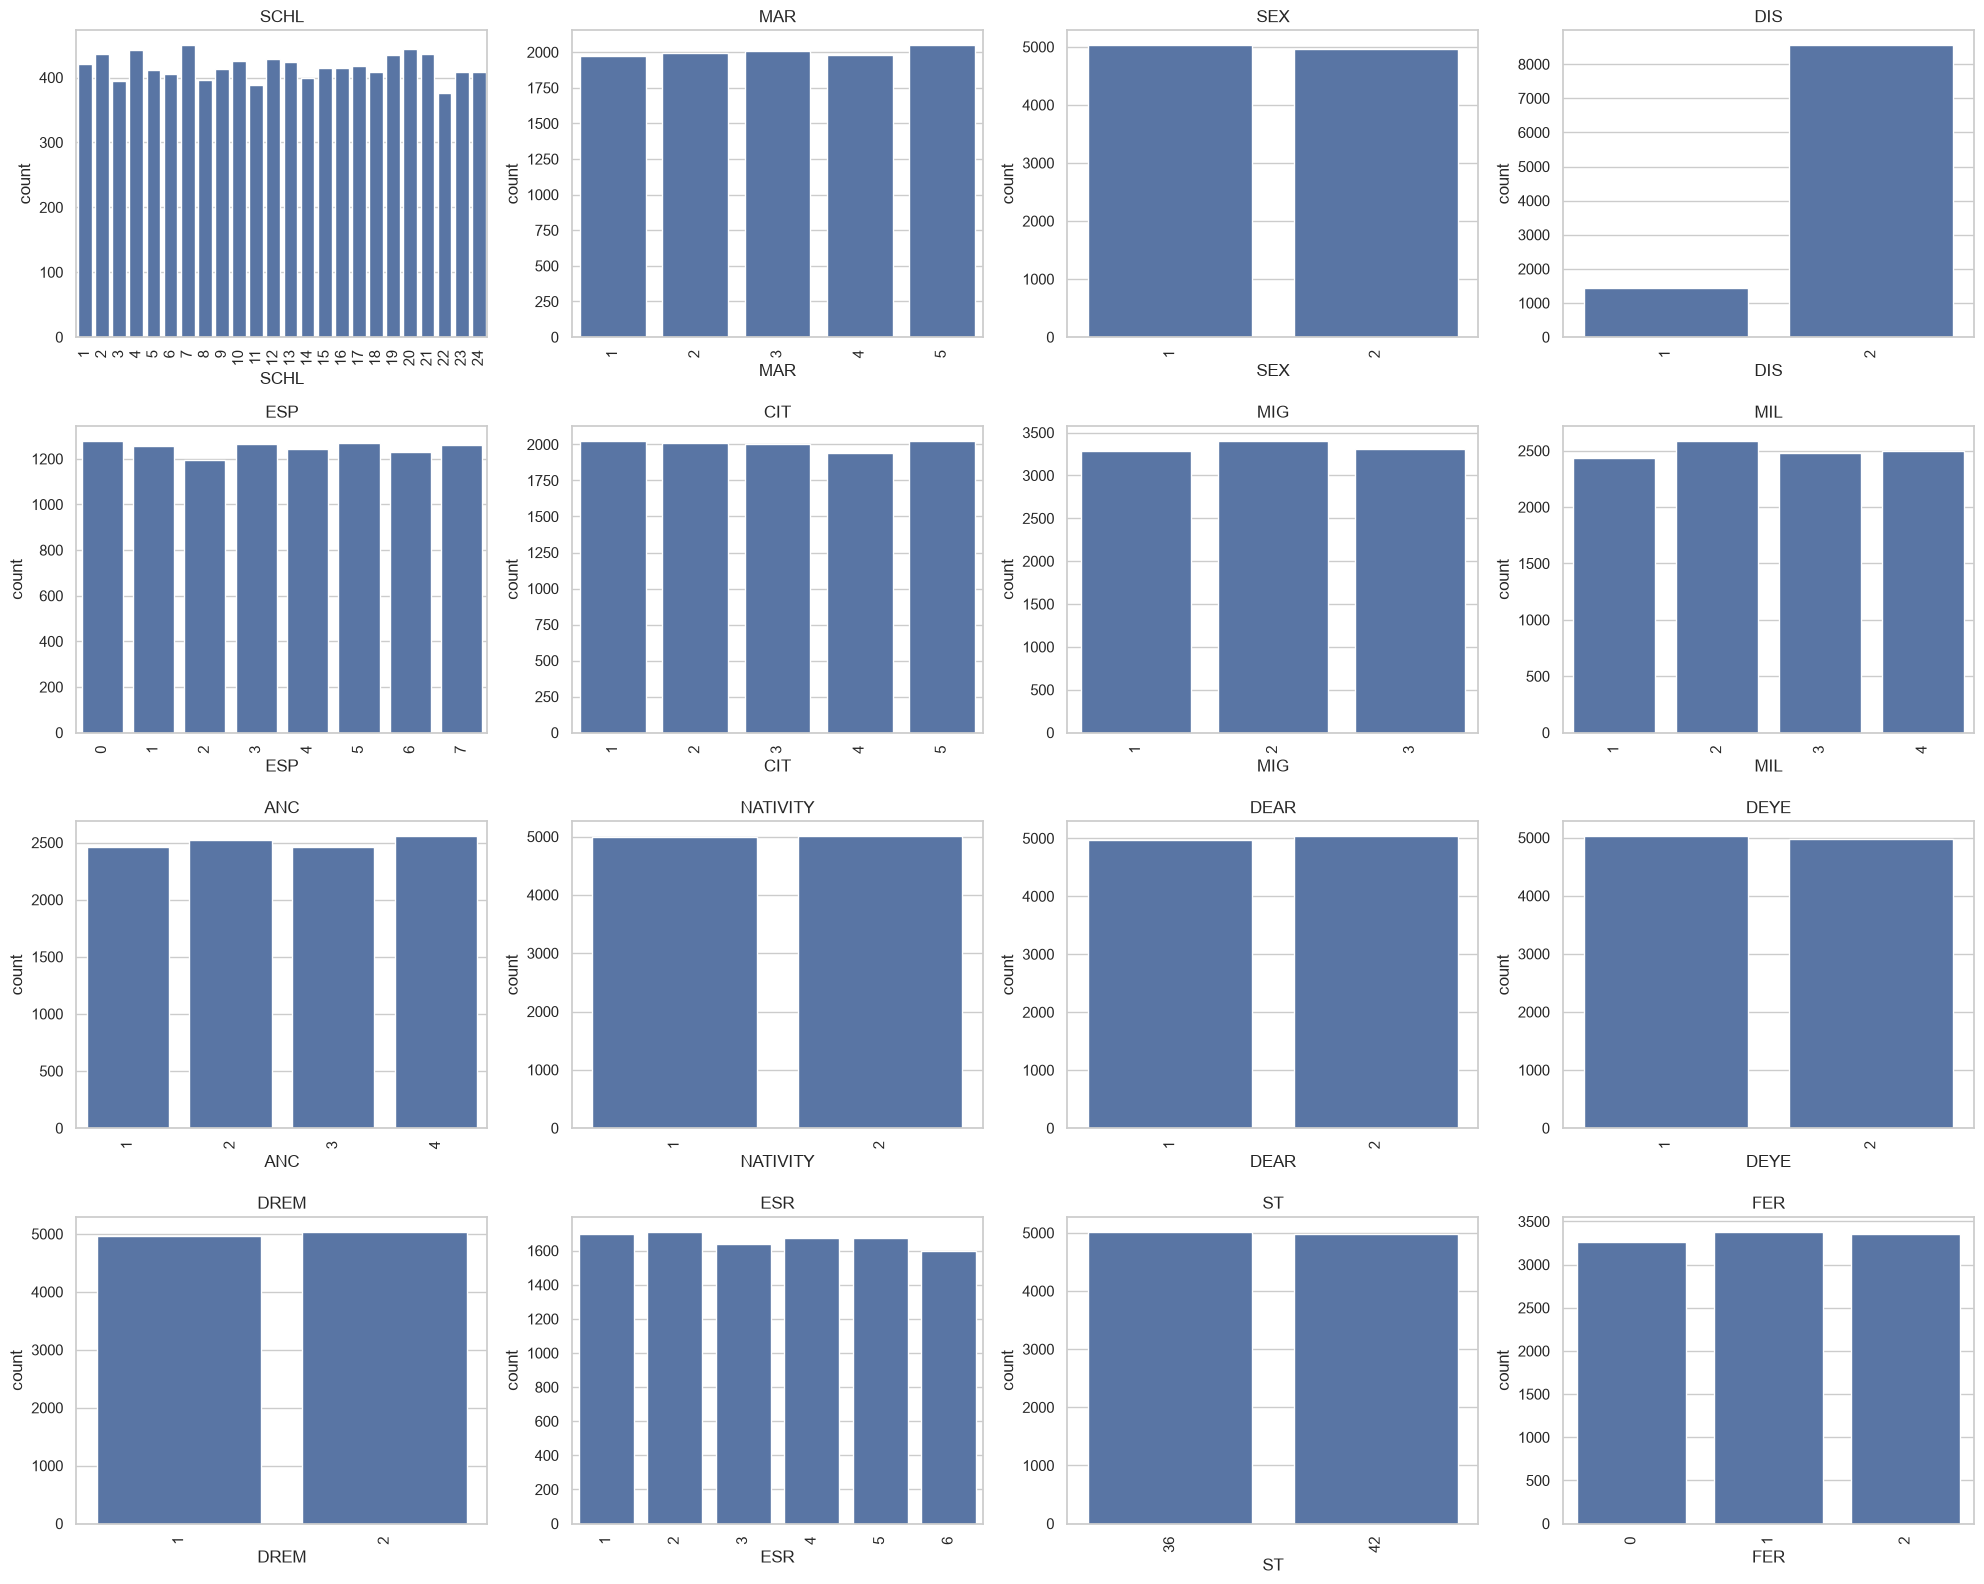

In [9]:
# Plot categorical feature distributions
fig, axes = plt.subplots(4, 4, figsize=(20, 16))

for feature, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(data=df_audit, x=feature, ax=ax)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [10]:
# Calculate coverage prevalence
coverage = df_audit["PUBCOV"].value_counts().sort_index()

coverage_summary = pd.DataFrame({
    "Count": coverage,
    "Percentage": coverage / len(df_audit) * 100
})

display(coverage_summary)

,Count,Percentage
PUBCOV,,
0,5889,58.89
1,4111,41.11


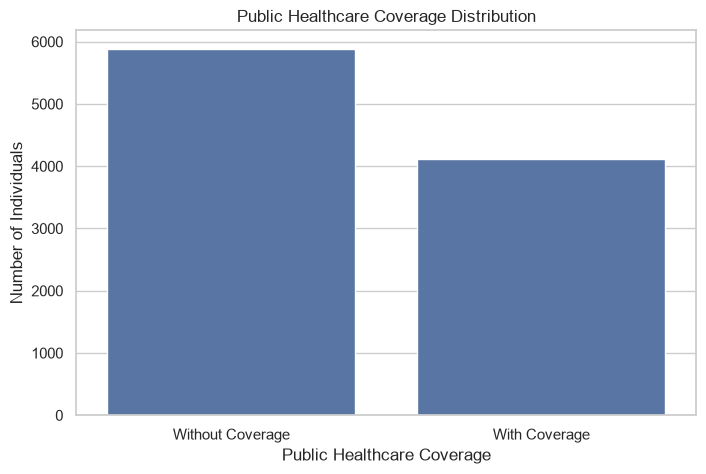

In [11]:
# Plot public healthcare coverage
plt.figure(figsize=(8, 5))

sns.countplot(data=df_audit, x="PUBCOV")

plt.title("Public Healthcare Coverage Distribution")
plt.xlabel("Public Healthcare Coverage")
plt.ylabel("Number of Individuals")
plt.xticks([0, 1], ["Without Coverage", "With Coverage"])

plt.show()

## 4. Baseline Model Predictions

In [12]:
# Generate baseline probability predictions
probs = vendor_api.predict_proba(df_audit)

# Generate predicted class labels
predictions = vendor_api.predict(df_audit)

# Inspect prediction outputs
print("Probability shape:", probs.shape)
print("Prediction shape:", predictions.shape)

# Display the first five probability predictions
display(probs[:5])

Probability shape: (10000, 2)
Prediction shape: (10000,)


array([[0.02467824, 0.97532176],
       [0.18181204, 0.81818796],
       [0.31327609, 0.68672391],
       [0.82272236, 0.17727764],
       [0.0733483 , 0.9266517 ]])

In [13]:
# Convert probability predictions into a DataFrame
df_probs = pd.DataFrame(
    probs,
    columns=["Class_0_Probability", "Class_1_Probability"]
)

# Display probability summary statistics
display(df_probs.describe())

,Class_0_Probability,Class_1_Probability
count,10000.000000,10000.000000
mean,0.587723,0.412277
std,0.308704,0.308704
min,0.006050,0.020421
25%,0.280406,0.148829
50%,0.717048,0.282952
75%,0.851171,0.719594
max,0.979579,0.993950


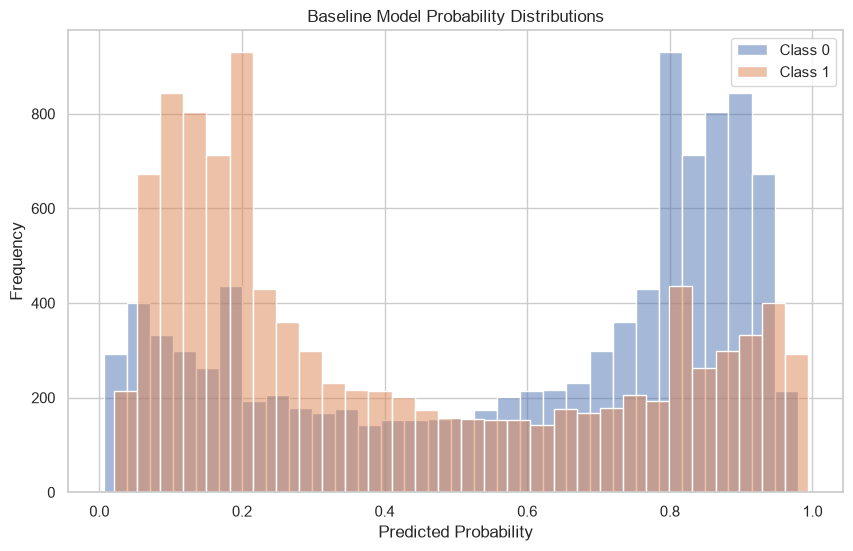

In [14]:
# Plot baseline probability distributions
plt.figure(figsize=(10, 6))

sns.histplot(
    df_probs["Class_0_Probability"],
    bins=30,
    label="Class 0",
    alpha=0.5
)

sns.histplot(
    df_probs["Class_1_Probability"],
    bins=30,
    label="Class 1",
    alpha=0.5
)

plt.title("Baseline Model Probability Distributions")
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.legend()

plt.show()

0    6448
1    3552
Name: count, dtype: int64

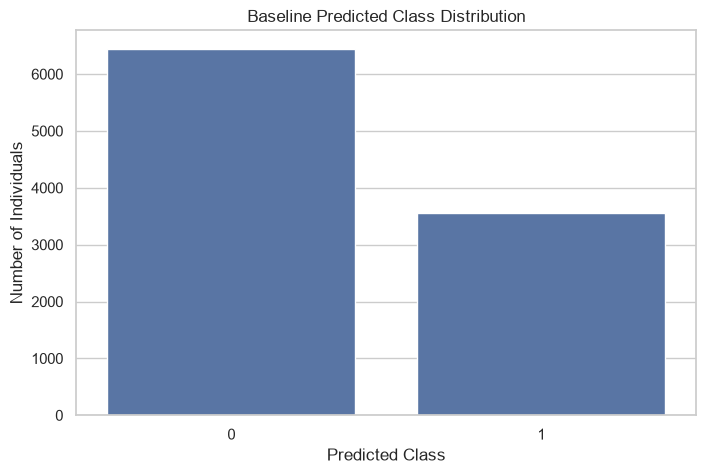

In [15]:
# Count predicted class labels
prediction_counts = pd.Series(predictions).value_counts()

display(prediction_counts)

# Visualize predicted class labels
plt.figure(figsize=(8, 5))

sns.countplot(x=predictions)

plt.title("Baseline Predicted Class Distribution")
plt.xlabel("Predicted Class")
plt.ylabel("Number of Individuals")

plt.show()